In [2]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [4]:
base_path = r"E:\kdt_0900_sal\ml\resource\dataset"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [5]:
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

print(len(train_dataset), len(test_dataset))

240 60


In [6]:
class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

## CNN을 활용해서 도형 분류하기 실습

## 데이터 로더

In [7]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [8]:
imgs, labels = next(iter(train_dataloader))

In [9]:
print(imgs.size())

torch.Size([64, 1, 64, 64])


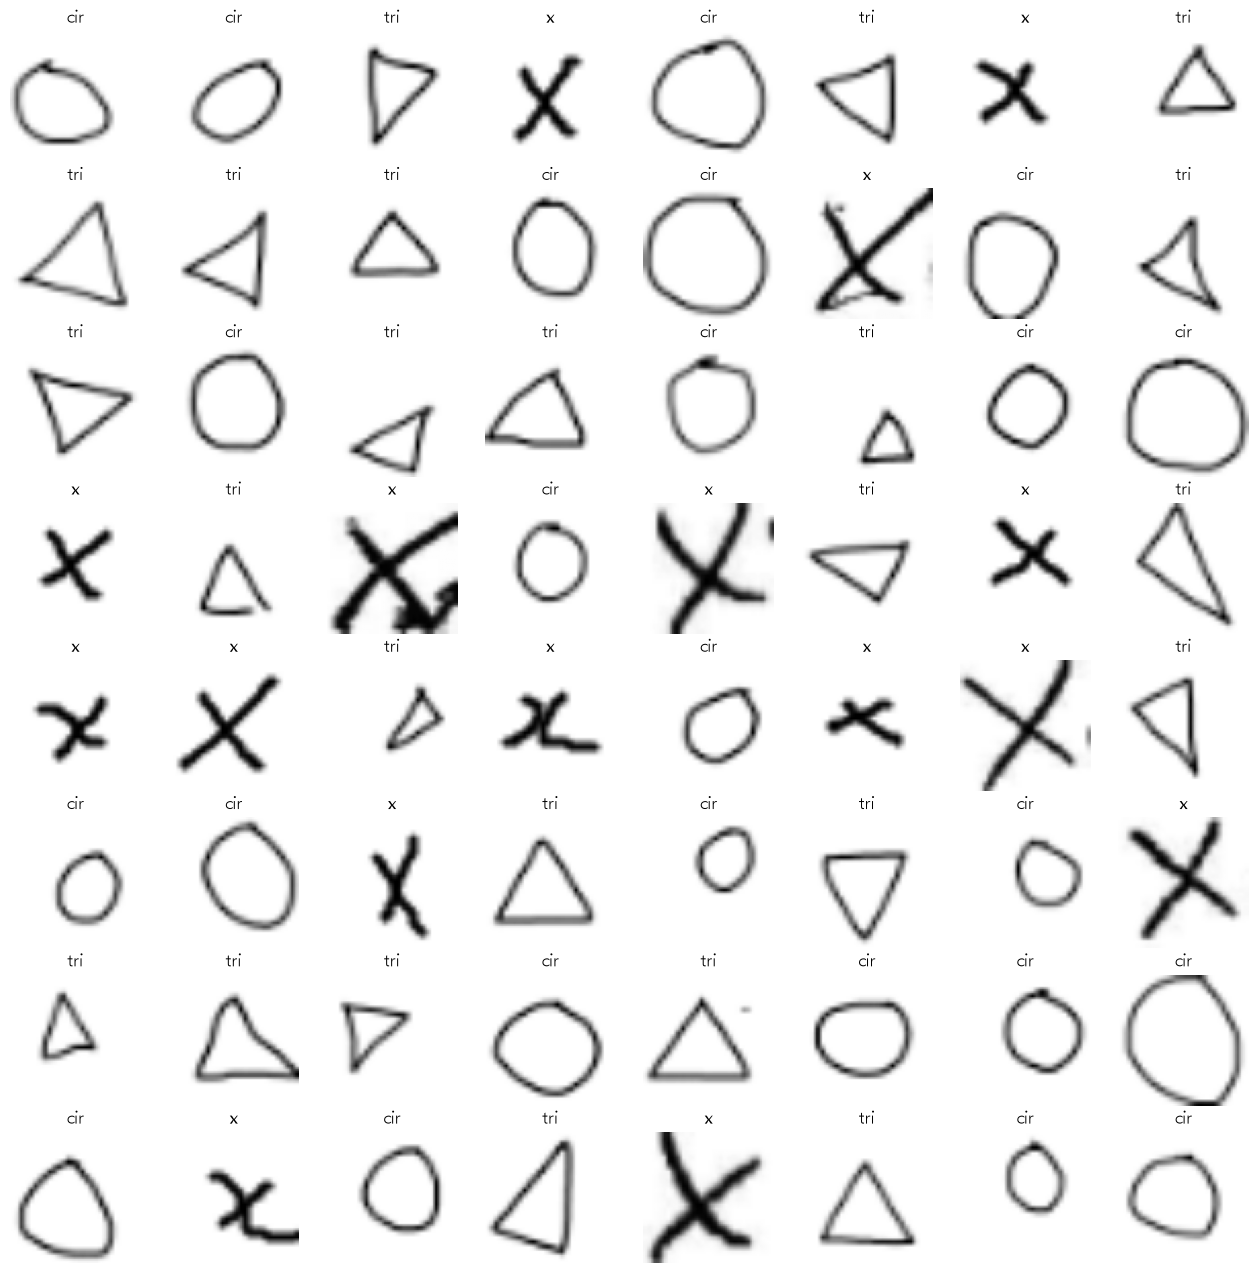

In [10]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow(img.reshape(64, 64), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.show()

In [11]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cpu


## CNN 모델 준비

In [12]:
class ConvNeuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), # 64 x 64
            nn.ReLU(), # 활성화 함수(선형 -> 비선형)
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 32, 32
            nn.Dropout(0.25),
            
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 16, 16
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 10)

    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [13]:
model = ConvNeuralNetwork().to(device)

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [15]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | LossL {loss:.4f} | Accuracy: {batch_acc:2f}")

    return running_loss / total, running_corrects / total

In [16]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size
    
    return running_loss / total, running_corrects / total

In [29]:
epochs = 10

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}")

Epoch: 0/10
[Train] Loss: 0.3220 | Accuracy: 84.17
[Test] Loss: 0.4831 | Accuracy: 68.33
Epoch: 1/10
[Train] Loss: 0.2481 | Accuracy: 88.75
[Test] Loss: 0.5567 | Accuracy: 75.00
Epoch: 2/10
[Train] Loss: 0.1800 | Accuracy: 93.75
[Test] Loss: 0.5189 | Accuracy: 73.33
Epoch: 3/10
[Train] Loss: 0.1676 | Accuracy: 92.92
[Test] Loss: 0.6784 | Accuracy: 70.00
Epoch: 4/10
[Train] Loss: 0.1450 | Accuracy: 95.00
[Test] Loss: 0.7773 | Accuracy: 68.33
Epoch: 5/10
[Train] Loss: 0.1407 | Accuracy: 94.17
[Test] Loss: 0.8806 | Accuracy: 71.67
Epoch: 6/10
[Train] Loss: 0.1193 | Accuracy: 95.00
[Test] Loss: 0.9650 | Accuracy: 73.33
Epoch: 7/10
[Train] Loss: 0.0939 | Accuracy: 96.67
[Test] Loss: 1.0017 | Accuracy: 73.33
Epoch: 8/10
[Train] Loss: 0.0826 | Accuracy: 97.92
[Test] Loss: 1.2572 | Accuracy: 78.33
Epoch: 9/10
[Train] Loss: 0.0578 | Accuracy: 98.33
[Test] Loss: 1.3560 | Accuracy: 70.00


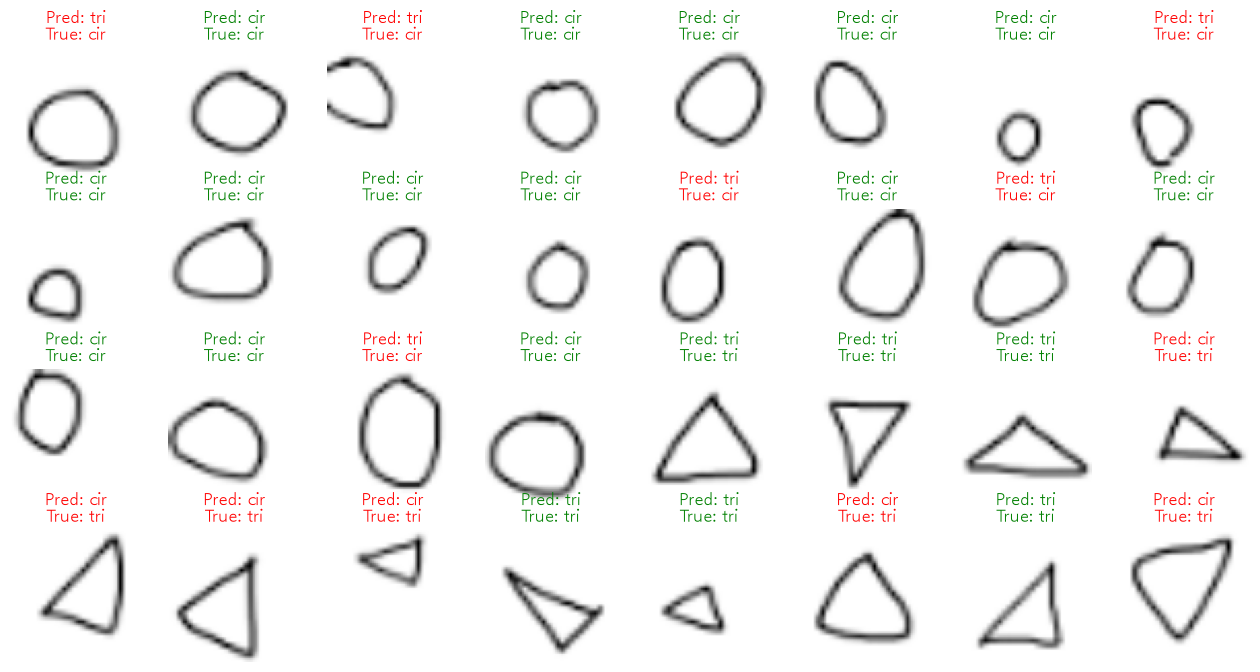

In [30]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.show()

In [31]:
img_path = r"E:\kdt_0900_sal\ml\resource\O.jpg"
img_path

'E:\\kdt_0900_sal\\ml\\resource\\O.jpg'

In [32]:
from PIL import Image

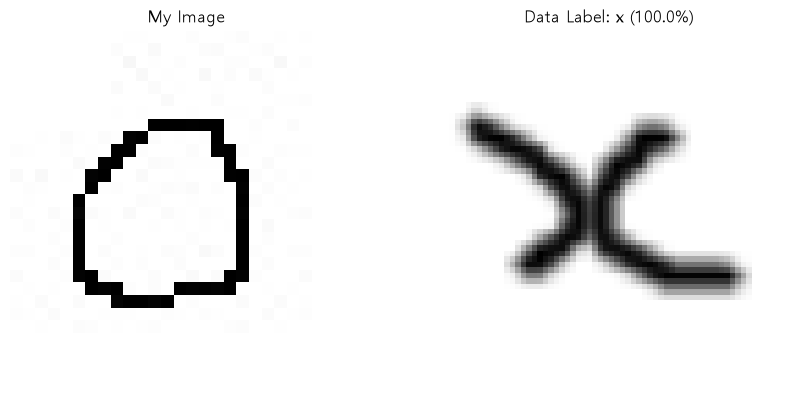

In [34]:
image = Image.open(img_path).convert("RGB")
input_tensor = test_transform(image)
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100


# 예측한 클래스와 같은 데이터 이미지 찾기
dataset_sample_img = None

for sample_imgs, sample_labels in train_dataloader:
    for sample_img, sample_label in zip(sample_imgs, sample_labels):

        if sample_label.item() == pred_idx:
            dataset_sample_img = sample_img
            break

    if dataset_sample_img is not None:
        break


# 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 0: 내 이미지
axes[0].imshow(image)
axes[0].set_title("My Image")
axes[0].axis("off")

# 1: 같은 라벨의 데이터 이미지
axes[1].imshow(dataset_sample_img.squeeze(), cmap="gray")
axes[1].set_title(
    f"Data Label: {pred_class} ({confidence:.1f}%)"
)
axes[1].axis("off")

plt.show()